# Week 02 · Data quality and splitting

Last week we used two tables. This week we use all of them, and we learn why that is harder than it sounds.

By the end of this notebook you will have:

- found what one row means in every table, and seen a join quietly add eighteen thousand rows
- audited the data with a checklist, and fixed each problem in a way you can repeat
- built one clean row per order from seven tables
- split the data **before** looking for patterns in the target
- watched Week 1's baselines fall apart when the test set is the future
- explored the training data with charts that point to next week's features

## Setup

In [3]:
import re
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from matplotlib.ticker import PercentFormatter

from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, "..")
from checkpoints import week_01

RANDOM_STATE = 42
DATA = Path("..") / "data" / "raw" / "olist"
assert DATA.exists(), "No data found. From the repository root, run: python data/download.py"

pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
ACCENT, WARM, GREY = "#3f51b5", "#e07b39", "#c9cdd6"

## 0. Start where we left off

Last week ended with a table of delivered orders, each labelled late or not. Instead of rebuilding it by hand, we load it from the checkpoint. This is how every lab starts from now on.

In [5]:
orders = week_01()
print(f"{len(orders):,} orders, {orders['is_late'].mean():.1%} late")
orders.head(3)

96,204 orders, 6.8% late


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_state,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,SP,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,BA,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,GO,0


## 1. Meet the other tables

We load everything else Olist gives us into one dictionary, so we can loop over the tables.

In [7]:
files = {
    "customers": "olist_customers_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_names": "product_category_name_translation.csv",
}
tables = {name: pd.read_csv(DATA / file) for name, file in files.items()}

### A quick profile of every table

Before anything else, four numbers per table: how many rows, how many columns, how many missing cells, and how many rows are exact copies of another row. A small function that we can run on all of them at once.

In [9]:
def profile(df):
    return pd.Series({
        "rows": len(df),
        "columns": df.shape[1],
        "missing cells": int(df.isna().sum().sum()),
        "duplicate rows": int(df.duplicated().sum()),
    })

profiles = pd.DataFrame({name: profile(df) for name, df in tables.items()}).T
profiles

,rows,columns,missing cells,duplicate rows
customers,99441,5,0,0
items,112650,7,0,0
payments,103886,5,0,0
reviews,99224,7,145903,0
products,32951,9,2448,0
sellers,3095,4,0,0
geolocation,1000163,5,0,261831
category_names,71,2,0,0


Two things stand out. The geolocation table has a million rows, and over a quarter of a million of them are exact copies. And the reviews table is full of gaps, because most customers leave a score without writing a comment.

### What does one row mean?

Every table has a **grain**: what one row stands for. One order, one item in an order, one payment. Getting the grain right is what makes a join safe.

A column, or a set of columns, identifies the grain if no combination of values appears twice. Let's test what we *think* the grain of each table is.

In [12]:
def is_key(df, columns):
    return not df.duplicated(subset=columns).any()

grains = {
    "customers": ["customer_id"],
    "items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "geolocation": ["geolocation_zip_code_prefix"],
    "category_names": ["product_category_name"],
}
for name, columns in grains.items():
    verdict = "yes" if is_key(tables[name], columns) else "NO"
    print(f"{name:15} one row per {' + '.join(columns):35} {verdict}")

customers       one row per customer_id                         yes
items           one row per order_id + order_item_id            yes
payments        one row per order_id + payment_sequential       yes
reviews         one row per review_id                           NO
products        one row per product_id                          yes
sellers         one row per seller_id                           yes
geolocation     one row per geolocation_zip_code_prefix         NO
category_names  one row per product_category_name               yes


Two surprises. **Reviews** are not one row per review: 814 review ids appear more than once, attached to different orders. And **geolocation** is not one row per zip code at all: it holds many points for each one. Neither is a problem as long as we know it. Both would be a problem if we joined without knowing.

## 2. Audit the data

We now go through the tables with a checklist, looking for six kinds of problem:

| Problem | Example |
|---|---|
| Missing | A product with no category |
| Impossible | A parcel handed to the carrier before it was bought |
| Inconsistent | The same city spelled three ways |
| Duplicated | The same row twice |
| Out of range | A Brazilian address with coordinates in Europe |
| Misnamed | A column called `lenght` |

For each problem found, we make one of three decisions: **fix it**, **flag it**, or **drop it**, and we write down which.

> **One rule for this whole section.** Cleaning fixes facts. It never *learns* from the data. Correcting a spelling is cleaning. Filling a missing weight with the median weight is not, because the median is learned from the data, and learning must only ever happen on the training set. That kind of step waits for Week 3, where it goes inside a pipeline.

### 2a. Misnamed columns

In [16]:
tables["products"].columns.tolist()

['product_id',
 'product_category_name',
 'product_name_lenght',
 'product_description_lenght',
 'product_photos_qty',
 'product_weight_g',
 'product_length_cm',
 'product_height_cm',
 'product_width_cm']

Olist's own column names contain a typo: `lenght`. Harmless, until someone spells it correctly in their code and gets a `KeyError`. We fix it once, at the source.

In [18]:
tables["products"] = tables["products"].rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})

### 2b. Missing and untranslated categories

Product categories are in Portuguese, with a separate table translating them into English. Two questions: how many products have no category, and does every category have a translation?

In [20]:
products = tables["products"]
names = tables["category_names"]

print("products with no category:", products["product_category_name"].isna().sum())

untranslated = set(products["product_category_name"].dropna()) - set(names["product_category_name"])
print("categories with no translation:", untranslated)

products with no category: 610
categories with no translation: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


The two gaps in Olist's translation table are easy to fill by hand. The 610 products with no category get the label `unknown`: we cannot recover the fact, but we can make it explicit.

In [22]:
translation = dict(zip(names["product_category_name"], names["product_category_name_english"]))
translation.update({
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_and_food_preparers",
})
products["category"] = products["product_category_name"].map(translation).fillna("unknown")
products["category"].value_counts().head(8)

category
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
Name: count, dtype: int64

### 2c. Inconsistent text

Sellers typed their own city names. Look at a few:

In [24]:
sellers = tables["sellers"]
odd = sellers["seller_city"].str.contains(r"[/,\\0-9]", regex=True)
sellers.loc[odd, "seller_city"].unique()

array(['auriflama/sp', 'sao paulo / sao paulo', '04482255',
       'novo hamburgo, rio grande do sul, brasil', 'cariacica / es',
       'sbc/sp', 'santo andre/sao paulo', 'sp / sp', 'maua/sao paulo',
       'mogi das cruzes / sp', 'rio de janeiro \\rio de janeiro',
       'barbacena/ minas gerais', 'rio de janeiro / rio de janeiro',
       'pinhais/pr', 'ribeirao preto / sao paulo',
       'carapicuiba / sao paulo', 'sao sebastiao da grama/sp',
       'rio de janeiro, rio de janeiro, brasil', 'jacarei / sao paulo'],
      dtype=object)

The same city appears as `sao paulo`, `sao paulo / sao paulo` and `sp / sp`. Some entries carry the state after a slash, one carries the whole country, and one seller typed a postcode where the city should be.

We write a function that puts every name into one form: lower case, accents removed, and anything after a slash or a comma dropped. The postcode we cannot fix, so it stays as it is. We have the seller's zip code in another column anyway.

In [26]:
def clean_city(name):
    name = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    name = re.split(r"[/,\\]", name)[0]
    return " ".join(name.lower().split())

print(clean_city("Sao Paulo / SP"), "|", clean_city("são paulo"), "|", clean_city("Novo Hamburgo, RS"))

before = sellers["seller_city"].nunique()
sellers["seller_city"] = sellers["seller_city"].map(clean_city)
print(f"distinct city names: {before} before, {sellers['seller_city'].nunique()} after")

sao paulo | sao paulo | novo hamburgo
distinct city names: 611 before, 589 after


### 2d. Duplicates and impossible coordinates

The geolocation table maps each zip code prefix to latitude and longitude, with many points per prefix. First the exact duplicates, then the points that cannot be right.

In [28]:
geo = tables["geolocation"].drop_duplicates()
print(f"{len(tables['geolocation']):,} rows, {len(geo):,} after dropping exact duplicates")

inside = geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34)
print("points outside Brazil:", (~inside).sum())
geo[~inside].head()

1,000,163 rows, 738,332 after dropping exact duplicates
points outside Brazil: 33


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ


Thirty-three Brazilian addresses placed in the ocean, in Europe, or somewhere in between. We drop those points, then reduce the table to **one location per zip prefix** by taking the median, which is not thrown off by a stray point.

In [30]:
zip_coords = geo[inside].groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].median()
print(f"{len(zip_coords):,} zip prefixes, one row each")

19,010 zip prefixes, one row each


### 2e. Impossible timelines

An order is bought, then handed to the carrier, then delivered. Any other order of events is impossible. Let's count the orders where time runs backwards.

In [32]:
purchase = orders["order_purchase_timestamp"]
carrier = orders["order_delivered_carrier_date"]
delivered = orders["order_delivered_customer_date"]

carrier_before_purchase = carrier < purchase
delivered_before_carrier = delivered < carrier
print("handed to carrier before it was bought:", carrier_before_purchase.sum())
print("delivered before it reached the carrier:", delivered_before_carrier.sum())

handed to carrier before it was bought: 165
delivered before it reached the carrier: 19


184 impossible orders. Do we drop them? Think about what the error touches. The broken field is the carrier date, which we never use: it is recorded after purchase, so it cannot be a feature, and our target depends only on the purchase, promised and delivery dates. So we **flag** these orders and keep them. If a later week relies on the carrier date, the flag is there.

The decision depends on the question. The same error would mean dropping the rows if we were predicting how long the carrier takes.

In [34]:
orders["bad_timeline"] = (carrier_before_purchase | delivered_before_carrier).astype(int)

### 2f. Two smaller findings

Nine payments of exactly zero, and a payment type called `not_defined` on three payments. Too few to matter, so we note them and move on. And two products have no weight: we leave those as missing, because filling them would mean learning from the data, which waits for Week 3.

In [36]:
payments = tables["payments"]
print("zero payments:", (payments["payment_value"] == 0).sum())
print(payments["payment_type"].value_counts())

zero payments: 9
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


## 3. One row per order

Our goal is one row per order, carrying everything we know at the moment of purchase. First, the obvious approach, to see why it fails.

### 3a. The join that lies

In [38]:
naive = (
    orders
    .merge(tables["items"], on="order_id")
    .merge(tables["payments"], on="order_id")
    .merge(tables["reviews"], on="order_id")
)
print(f"{len(orders):,} orders became {len(naive):,} rows")

96,204 orders became 114,521 rows


Over eighteen thousand extra rows, and no error. An order with two items and two payments becomes four rows, one for every pairing. Count late orders now and you count some of them four times. Train on this and the model sees some orders far more often than others.

The rule: **bring every table to the grain you want before joining it.** For us that is one row per order, so the many-rows-per-order tables get summarised first.

A word on reviews: we leave them out entirely. Look at when they are written:

In [40]:
reviews = tables["reviews"].merge(orders[["order_id", "order_delivered_customer_date"]], on="order_id")
written_after = pd.to_datetime(reviews["review_creation_date"]) >= reviews["order_delivered_customer_date"].dt.normalize()
print(f"reviews written on or after the delivery day: {written_after.mean():.1%}")

reviews written on or after the delivery day: 94.7%


Almost every review exists only after the parcel has arrived. At the moment of purchase, none of it exists. The whole table would leak.

### 3b. Items, to one row per order

An order can contain several items, sometimes from several sellers. We summarise them: how many items, how many sellers, the total price, freight and weight. For the seller and the category we take the **first item** in the order, since nine orders in ten have only one.

In [42]:
items = tables["items"].merge(products[["product_id", "category", "product_weight_g"]], on="product_id", how="left")

per_order = items.groupby("order_id").agg(
    n_items=("order_item_id", "size"),
    n_sellers=("seller_id", "nunique"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_weight_g=("product_weight_g", lambda w: w.sum(min_count=1)),
)
per_order.head()

,n_items,n_sellers,total_price,total_freight,total_weight_g
order_id,,,,,
00010242fe8c5a6d1ba2dd792cb16214,1,1,58.90,13.29,650.0
00018f77f2f0320c557190d7a144bdd3,1,1,239.90,19.93,30000.0
000229ec398224ef6ca0657da4fc703e,1,1,199.00,17.87,3050.0
00024acbcdf0a6daa1e931b038114c75,1,1,12.99,12.79,200.0
00042b26cf59d7ce69dfabb4e55b4fd9,1,1,199.90,18.14,3750.0


In [43]:
first_item = items[items["order_item_id"] == 1].set_index("order_id")[["seller_id", "category"]]
first_item = first_item.join(
    sellers.set_index("seller_id")[["seller_zip_code_prefix", "seller_city", "seller_state"]],
    on="seller_id",
)
first_item.head(3)

,seller_id,category,seller_zip_code_prefix,seller_city,seller_state
order_id,,,,,
00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,cool_stuff,27277,volta redonda,SP
00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,pet_shop,3471,sao paulo,SP
000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,furniture_decor,37564,borda da mata,MG


### 3c. Payments, to one row per order

Same idea. How many payments, the total paid, the most instalments used, and the type of the first payment.

In [45]:
per_payment = payments.groupby("order_id").agg(
    n_payments=("payment_sequential", "size"),
    total_paid=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
)
per_payment["payment_type"] = payments.sort_values("payment_sequential").groupby("order_id")["payment_type"].first()
per_payment.head(3)

,n_payments,total_paid,max_installments,payment_type
order_id,,,,
00010242fe8c5a6d1ba2dd792cb16214,1,72.19,2,credit_card
00018f77f2f0320c557190d7a144bdd3,1,259.83,3,credit_card
000229ec398224ef6ca0657da4fc703e,1,216.87,5,credit_card


### 3d. Join, and check every time

Every table is now at the grain of one row per order, or one row per zip code. A join can still go wrong, so we wrap it in a small function that refuses to change the number of rows.

In [47]:
def join_checked(left, right, **kwargs):
    joined = left.merge(right, how="left", **kwargs)
    assert len(joined) == len(left), f"join changed the rows: {len(left):,} to {len(joined):,}"
    return joined

customer_coords = zip_coords.rename(columns=lambda c: c.replace("geolocation", "customer"))
seller_coords = zip_coords.rename(columns=lambda c: c.replace("geolocation", "seller"))

df = join_checked(orders, tables["customers"][["customer_id", "customer_unique_id", "customer_zip_code_prefix"]], on="customer_id")
df = join_checked(df, per_order, left_on="order_id", right_index=True)
df = join_checked(df, first_item, left_on="order_id", right_index=True)
df = join_checked(df, per_payment, left_on="order_id", right_index=True)
df = join_checked(df, customer_coords, left_on="customer_zip_code_prefix", right_index=True)
df = join_checked(df, seller_coords, left_on="seller_zip_code_prefix", right_index=True)

print(df.shape)

(96204, 31)


### 3e. What is still missing?

After joining seven tables, a quick look at the gaps that remain.

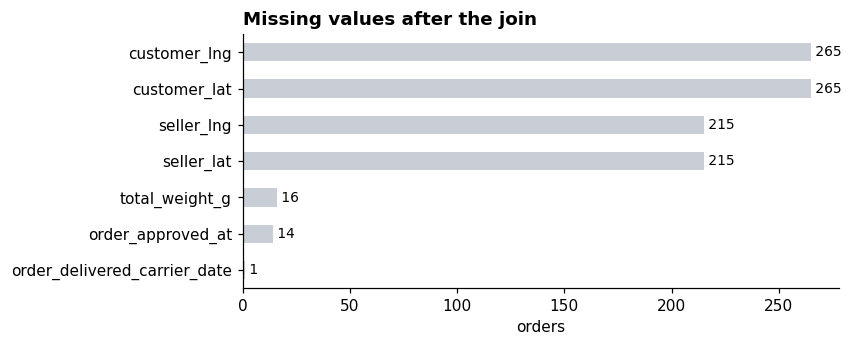

In [49]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values()

ax = missing.plot.barh(color=GREY, figsize=(7, 3))
for i, value in enumerate(missing):
    ax.text(value, i, f" {value}", va="center", fontsize=9)
ax.set_title("Missing values after the join")
ax.set_xlabel("orders")
plt.show()

Very little, and every gap has a known cause: a few zip codes with no location, two products with no weight, a handful of orders never approved. We leave them missing. Filling them is a job for Week 3's pipeline.

## 4. Split before you look

There are two kinds of looking.

**Structural checks** ask about the data itself: types, gaps, duplicates, impossible dates. They never look at the target, so doing them on everything, as we just did, is fine.

**Target exploration** asks which things go with lateness. That is already learning from the labels. If we do it on all the data, what we see in the test set quietly shapes the features we build, and the test set stops being unseen.

So we split now, before exploring the target. A confession: in Week 1 we charted lateness by state across all twenty months. Fine for a first look, but from here on, target exploration happens on the training set only.

The split follows time, because the model will be used on future orders:

| Part | Purchased | Used for |
|---|---|---|
| **train** | January 2017 to February 2018 | Learning, and exploring |
| **valid** | March and April 2018 | Comparing options and making choices |
| **test** | May to August 2018 | One final, honest score |

In [52]:
purchase = df["order_purchase_timestamp"]
df["split"] = "test"
df.loc[purchase < "2018-05-01", "split"] = "valid"
df.loc[purchase < "2018-03-01", "split"] = "train"

df.groupby("split", sort=False).agg(orders=("is_late", "size"), late_rate=("is_late", "mean")).round(3)

,orders,late_rate
split,,
train,57051,0.066
test,25352,0.044
valid,13801,0.118


The late rate is 6.6% in training, 11.8% in validation, and 4.4% in test. Three parts of the same dataset, three different worlds. This chart shows why:

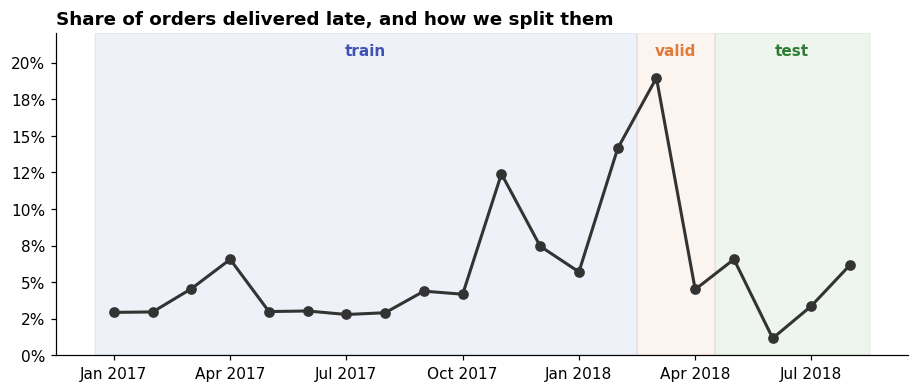

In [54]:
monthly = df.groupby(df["order_purchase_timestamp"].dt.to_period("M"))["is_late"].mean()
periods = monthly.index

fig, ax = plt.subplots(figsize=(10, 3.8))
colours = {"train": ACCENT, "valid": WARM, "test": "#2e7d32"}
starts = {"train": "2017-01", "valid": "2018-03", "test": "2018-05"}
ends = {"train": "2018-02", "valid": "2018-04", "test": "2018-08"}
for part in ["train", "valid", "test"]:
    a = periods.get_loc(pd.Period(starts[part]))
    b = periods.get_loc(pd.Period(ends[part]))
    ax.axvspan(a - 0.5, b + 0.5, color=colours[part], alpha=0.08)
    ax.text((a + b) / 2, 0.205, part, ha="center", color=colours[part], fontweight="bold")

ax.plot(range(len(monthly)), monthly.values, color="#333333", marker="o", lw=2)
ax.set_xticks(range(0, len(periods), 3))
ax.set_xticklabels([p.strftime("%b %Y") for p in periods[::3]])
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.22)
ax.set_title("Share of orders delivered late, and how we split them")
plt.show()

Validation catches the spike of early 2018. Test covers the calm months that follow. A model tuned to look good on validation may be tuned to a crisis that has already passed. That is not a flaw in our split. It is what the future is like, and a random split would have hidden it from us.

From now on, `train` is the only part we explore.

In [56]:
train = df[df["split"] == "train"].copy()
print(f"{len(train):,} training orders")

57,051 training orders


## 5. Explore the training data

Five charts, each asking one question. After each one, the question that matters: **what feature does this suggest?** We collect the answers, and next week we build them.

### 5a. Brazil, drawn by its customers

Every training order has the customer's location. Draw them all as faint dots and the shape of the country appears. On top, a honeycomb of the late rate: each cell is coloured by the share of its orders that arrived late. Cells with fewer than 15 orders are left out, because small groups lie.

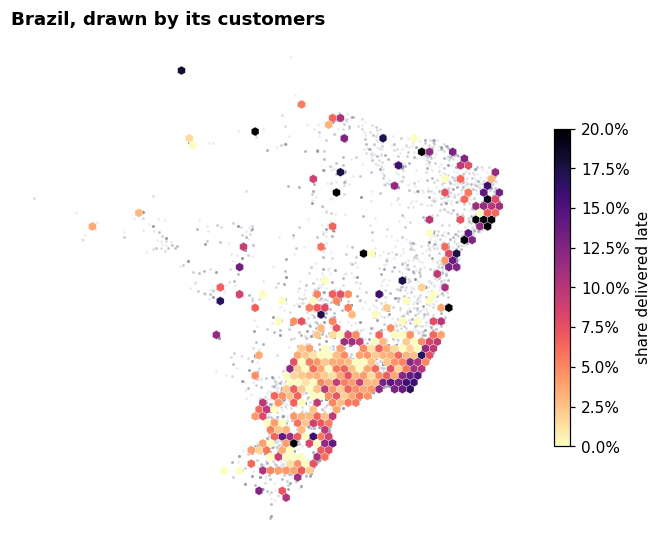

In [59]:
located = train.dropna(subset=["customer_lat", "customer_lng"])

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.scatter(located["customer_lng"], located["customer_lat"], s=3, color="#8a90a0", alpha=0.18, linewidths=0, zorder=1)
cells = ax.hexbin(
    located["customer_lng"], located["customer_lat"], C=located["is_late"],
    reduce_C_function=np.mean, gridsize=60, mincnt=15,
    cmap="magma_r", vmin=0, vmax=0.2, linewidths=0.2, edgecolors="white", zorder=2,
)
fig.colorbar(cells, ax=ax, shrink=0.5, format=PercentFormatter(1), label="share delivered late")
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Brazil, drawn by its customers")
plt.show()

The south and the São Paulo region are pale. The northeastern coast glows dark, and so does the area around Rio de Janeiro. But look closer: darkness does not simply follow distance, and neighbouring cells can differ a lot.

**Feature suggested:** location matters at a finer level than the state. The customer's coordinates, and above all the distance between seller and customer, are worth building next week.

### 5b. What was promised, and what happened

For each order, the days promised against the days it actually took. Orders on the diagonal arrived exactly on the promised day. Below it: early. Above it: late.

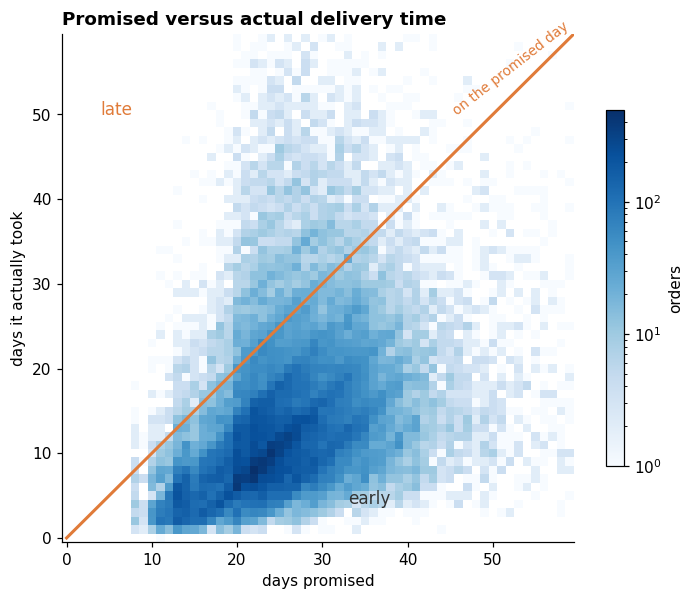

median promised: 25 days, median actual: 11 days
arrived a week or more early: 82%


In [62]:
purchase_day = train["order_purchase_timestamp"].dt.normalize()
promised_days = (train["order_estimated_delivery_date"] - purchase_day).dt.days
actual_days = (train["order_delivered_customer_date"].dt.normalize() - purchase_day).dt.days

bins = np.arange(0, 61) - 0.5
fig, ax = plt.subplots(figsize=(7.5, 6))
*_, image = ax.hist2d(promised_days, actual_days, bins=[bins, bins], cmap="Blues", norm=LogNorm(), cmin=1)
fig.colorbar(image, ax=ax, shrink=0.7, label="orders")
ax.plot([0, 60], [0, 60], color=WARM, lw=2)
ax.text(45, 50, "on the promised day", color=WARM, rotation=38, fontsize=9)
ax.text(33, 4, "early", fontsize=11, color="#333333")
ax.text(4, 50, "late", fontsize=11, color=WARM)
ax.set_xlabel("days promised")
ax.set_ylabel("days it actually took")
ax.set_title("Promised versus actual delivery time")
plt.show()

print(f"median promised: {promised_days.median():.0f} days, median actual: {actual_days.median():.0f} days")
print(f"arrived a week or more early: {(promised_days - actual_days >= 7).mean():.0%}")

The bulk of orders sits far below the line. Olist promises about 25 days and usually delivers in 11: more than four orders in five arrive a week or more early. The promise is padded on purpose.

That explains why the promised window alone was a weak feature in Week 1. The padding already absorbs the expected delivery time. A late order is one where something went wrong *beyond* the usual.

**Feature suggested:** what matters is how the promise compares with how long a trip like this usually takes. An estimate of the *typical* delivery time for the route, set against the promise, is worth trying.

### 5c. When Brazil shops

Orders by day of the week and hour of the day.

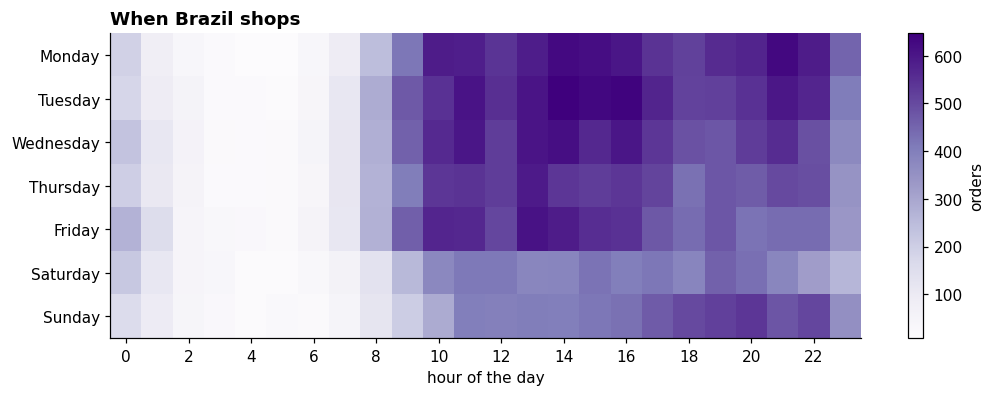

late rate across the busy hours: 5.7% to 7.5%
at 3 in the morning: 3.8%, from only 158 orders


In [65]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
volume = pd.crosstab(
    train["order_purchase_timestamp"].dt.day_name(),
    train["order_purchase_timestamp"].dt.hour,
).reindex(days)

fig, ax = plt.subplots(figsize=(11, 3.6))
image = ax.imshow(volume, aspect="auto", cmap="Purples")
ax.set_yticks(range(7))
ax.set_yticklabels(days)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of the day")
fig.colorbar(image, ax=ax, label="orders")
ax.set_title("When Brazil shops")
plt.show()

late_by_hour = train.groupby(train["order_purchase_timestamp"].dt.hour)["is_late"].agg(["mean", "size"])
busy = late_by_hour[late_by_hour["size"] >= 1000]
print(f"late rate across the busy hours: {busy['mean'].min():.1%} to {busy['mean'].max():.1%}")
print(f"at 3 in the morning: {late_by_hour.loc[3, 'mean']:.1%}, from only {late_by_hour.loc[3, 'size']} orders")

A beautiful pattern: busy weekday afternoons and evenings, quiet nights, calmer weekends. Tuesday at two in the afternoon is the peak. But the late rate hardly moves: across the busy hours it stays between about 6% and 7.5%. The extreme at three in the morning comes from only 158 orders. Small groups lie, again.

**Feature suggested:** probably none. When people shop is striking, but it does not say much about whether the parcel arrives late. A chart that says *not this* is still a useful chart.

### 5d. Same state, or not

Does it matter whether the seller and the customer are in the same state?

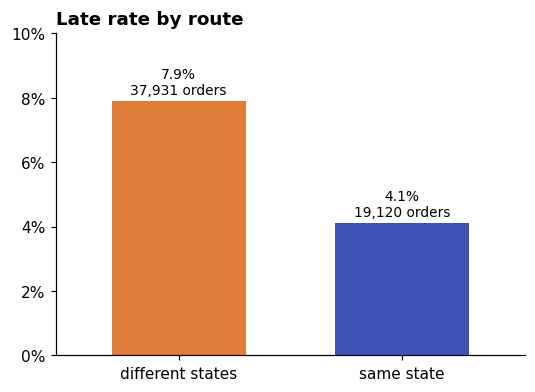

In [68]:
same_state = train["customer_state"] == train["seller_state"]
by_route = train.groupby(same_state)["is_late"].agg(["mean", "size"])
by_route.index = ["different states", "same state"]

ax = by_route["mean"].plot.bar(color=[WARM, ACCENT], rot=0, figsize=(5.5, 3.8), width=0.6)
for i, (rate, count) in enumerate(zip(by_route["mean"], by_route["size"])):
    ax.text(i, rate + 0.002, f"{rate:.1%}\n{count:,} orders", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.1)
ax.set_title("Late rate by route")
plt.show()

Orders that cross a state border are late almost twice as often: 7.9% against 4.1%. This is the strongest single pattern in the training data so far, and it takes one line to compute.

**Feature suggested:** `same_state`, directly. And it is a rough version of something better: the actual distance between seller and customer, which we already have the coordinates for.

### 5e. Categories

The fifteen most common categories, ordered by late rate.

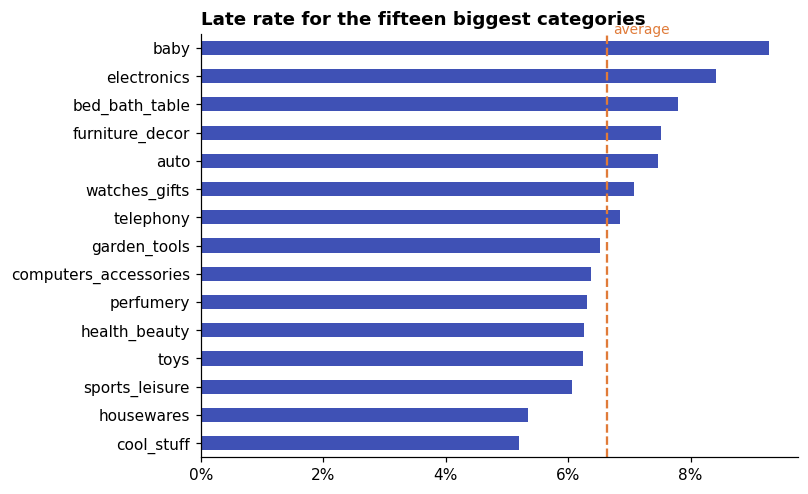

In [71]:
top = train["category"].value_counts().head(15).index
by_category = train[train["category"].isin(top)].groupby("category")["is_late"].mean().sort_values()

ax = by_category.plot.barh(color=ACCENT, figsize=(7, 5))
ax.axvline(train["is_late"].mean(), color=WARM, ls="--", lw=1.5)
ax.text(train["is_late"].mean() + 0.001, 14.5, "average", color=WARM, fontsize=9)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel("")
ax.set_title("Late rate for the fifteen biggest categories")
plt.show()

Baby products and electronics run late more often than the average, around 9% and 8%. Cool stuff and housewares less, around 5%. A real spread, but a modest one, and there are over seventy categories, many of them tiny.

**Feature suggested:** the category, but carefully. Seventy categories cannot be fed to a model as they are, and turning them into numbers using the late rate itself is exactly the kind of step that can leak. Week 3 does it properly.

## 6. Random versus time

Now the question Week 1 left open. Here are last week's three rungs in one function. It returns PR AUC for each rung, the positive rate of the test data, and the **lift**: PR AUC divided by the positive rate. Lift is the fair way to compare, because the floor moves when the positive rate changes. A lift of 1 means no better than guessing.

In [74]:
def ladder(train_part, test_part):
    y = test_part["is_late"]
    rate = train_part.groupby("customer_state")["is_late"].mean()
    average = train_part["is_late"].mean()

    def with_features(frame):
        frame = frame.assign(state_rate=frame["customer_state"].map(rate).fillna(average))
        frame["window_days"] = (frame["order_estimated_delivery_date"] - frame["order_purchase_timestamp"].dt.normalize()).dt.days
        frame["weekday"] = frame["order_purchase_timestamp"].dt.dayofweek
        frame["hour"] = frame["order_purchase_timestamp"].dt.hour
        return frame[["window_days", "weekday", "hour", "state_rate"]]

    tree = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=RANDOM_STATE)
    tree.fit(with_features(train_part), train_part["is_late"])

    scores = pd.Series({
        "rule": average_precision_score(y, test_part["customer_state"].map(rate).fillna(average)),
        "tree": average_precision_score(y, tree.predict_proba(with_features(test_part))[:, 1]),
    })
    return pd.DataFrame({"PR AUC": scores, "positive rate": y.mean(), "lift": scores / y.mean()}).round(3)

First, Week 1's random split, exactly as it was:

In [76]:
random_train, random_test = train_test_split(df, test_size=0.2, stratify=df["is_late"], random_state=RANDOM_STATE)
ladder(random_train, random_test)

,PR AUC,positive rate,lift
rule,0.102,0.068,1.506
tree,0.102,0.068,1.503


Now the honest version: learn from the past, score on the future.

In [78]:
past, valid, future = (df[df["split"] == part] for part in ["train", "valid", "test"])

print("scored on validation")
display(ladder(past, valid))
print("scored on test")
display(ladder(past, future))

scored on validation


,PR AUC,positive rate,lift
rule,0.186,0.118,1.569
tree,0.195,0.118,1.648


scored on test


,PR AUC,positive rate,lift
rule,0.048,0.044,1.102
tree,0.052,0.044,1.178


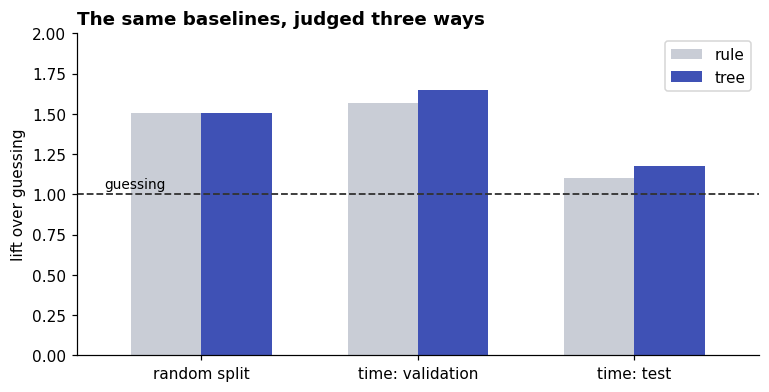

In [79]:
results = pd.DataFrame({
    "random split": ladder(random_train, random_test)["lift"],
    "time: validation": ladder(past, valid)["lift"],
    "time: test": ladder(past, future)["lift"],
}).T

ax = results.plot.bar(color=[GREY, ACCENT], rot=0, figsize=(8, 3.8), width=0.65)
ax.axhline(1, color="#333333", ls="--", lw=1.2)
ax.text(-0.45, 1.04, "guessing", fontsize=9, ha="left")
ax.set_ylabel("lift over guessing")
ax.set_ylim(0, 2)
ax.set_title("The same baselines, judged three ways")
plt.show()

On the random split, both rungs look about one and a half times better than guessing. Trained on the past and scored on the most recent months, they fall to barely above guessing: a lift of 1.1 to 1.2.

Nothing about the models changed. Only the question we asked of them. The random split let the model learn from months it was then tested on, including their spikes and their calm. The time split asks what we actually need to know: **will patterns learned from the past still hold next month?** For Week 1's features, mostly not.

This is the most important result of the week. It says the easy features are exhausted, and it gives Week 3 a clear job.

## 7. The same person twice

One more reason a random split can flatter: the same customer on both sides. Olist gives every order a fresh `customer_id`, but `customer_unique_id` is the real person.

In [82]:
orders_per_person = df.groupby("customer_unique_id").size()
print("people with more than one order:", (orders_per_person > 1).sum())

same_day = df.groupby(["customer_unique_id", df["order_purchase_timestamp"].dt.date])["is_late"].agg(["size", "nunique"])
same_day = same_day[same_day["size"] > 1]
print("orders sharing a buyer and a day with another order:", same_day["size"].sum())
print(f"of those groups, all labels agree: {(same_day['nunique'] == 1).mean():.0%}")

people with more than one order: 2789
orders sharing a buyer and a day with another order: 1743
of those groups, all labels agree: 92%


Many of these are one shopping basket split into several orders, one per seller. Placed together, shipped together, and late together nine times out of ten. Near copies.

How many of them land on both sides of each split?

In [84]:
seen_in_training = set(random_train["customer_unique_id"])
print(f"random split: test orders whose buyer is also in training: {random_test['customer_unique_id'].isin(seen_in_training).sum():,}")

seen_in_past = set(past["customer_unique_id"])
print(f"time split:   test orders whose buyer is also in training: {future['customer_unique_id'].isin(seen_in_past).sum():,}")

random split: test orders whose buyer is also in training: 986
time split:   test orders whose buyer is also in training: 420


Under the random split, almost a thousand test orders share a buyer with training orders, some of them from the very same basket. Under the time split, far fewer, and a basket can never straddle the line, since its orders are placed on the same day.

For *our* question, a returning customer in the future is perfectly realistic, so the time split is already the right one. But when you will predict for **new** people, patients, or shops, you need a **grouped split**, which keeps every row of one person on the same side:

In [86]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, groups=df["customer_unique_id"]))

shared = set(df.iloc[train_idx]["customer_unique_id"]) & set(df.iloc[test_idx]["customer_unique_id"])
print("buyers on both sides of a grouped split:", len(shared))

buyers on both sides of a grouped split: 0


Zero, by construction. Which split is right depends on one question: **who, or when, will the model be used on?** Future orders: split by time. New people: split by group. Both: split by time, and check the groups.

## 8. Ready for next week

Next week starts from the table we built today. The checkpoint function rebuilds it from the raw files. Let's confirm it matches.

In [89]:
from checkpoints import week_02

check = week_02()
merged = check.merge(df, on="order_id", suffixes=("", "_ours"))

print("same orders:     ", len(merged) == len(check) == len(df))
print("same split:      ", (merged["split"] == merged["split_ours"]).all())
print("same labels:     ", (merged["is_late"] == merged["is_late_ours"]).all())
print("same total price:", np.allclose(merged["total_price"], merged["total_price_ours"]))

same orders:      True
same split:       True
same labels:      True
same total price: True


## What we learned

- **Every table has a grain.** Know what one row means before joining, and summarise to your target grain first.
- **A join that adds rows raises no error.** Check the row count after every join.
- **Audit with a checklist:** missing, impossible, inconsistent, duplicated, out of range, misnamed. Then fix, flag, or drop, and write down which.
- **Cleaning fixes facts. It never learns from the data.** Filling gaps with learned values waits for a pipeline.
- **Split before you explore the target.** Structural checks can use everything. Patterns in the target, only the training set.
- **Split the way the model will be used.** Future orders: by time. New people: by group.
- **A random split can make a weak model look useful.** Ours went from 1.5 times better than guessing to barely better.

**For next week:** the charts suggested distance between seller and customer, same state or not, how the promise compares with a typical delivery, and the category. Week 3 builds them, inside a pipeline that cannot leak.